In [ ]:
!pip uninstall -y numpy torch torchvision transformers jax jaxlib tensorflow pydantic

In [ ]:
!pip install "numpy<2.0.0,>=1.24.4" \
             "torch==2.3.1" \
             "torchvision==0.18.1" \
             "transformers==4.41.2" \
             "jax==0.4.26" \
             "jaxlib==0.4.26" \
             "pydantic>=2.10.1,<2.11.0" \
             "accelerate>=0.28.0" \
             "spaces==0.30.4"

In [ ]:
!pip install  huggingface_hub

!pip install imagecorruptions
!pip install --upgrade scikit-image

In [ ]:
import os

# Environment path for imagecorruptions package
file_path = '/usr/local/lib/python3.12/dist-packages/imagecorruptions/corruptions.py'

if os.path.exists(file_path):
    # Read file contents
    with open(file_path, 'r') as file:
        file_data = file.read()

    # Patch deprecated parameter calls
    file_data = file_data.replace('multichannel=True', 'channel_axis=-1')
    file_data = file_data.replace('multichannel=False', 'channel_axis=None')
    
    # Overwrite patched file
    with open(file_path, 'w') as file:
        file.write(file_data)
        
    print("✅ Successfully patched corruptions.py via Python!")
else:
    print("❌ File not found. Please verify the file path.")

> **Note**: Execute environment setup cells above once upon fresh kernel initialization, then restart runtime if dependencies were updated.


In [1]:
from datasets import load_dataset
import matplotlib.pyplot as plt
from pprint import pprint
import pickle
import numpy as np
np.float_ = np.float64

from pycocotools import mask as mask_util
from PIL import Image
import albumentations as A
import random
import torch
import os
import cv2

In [2]:
def set_seed(seed=42):
    """
    Fix all random sources to ensure reproducible benchmark results.
    """
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # Multi-GPU support
    
    # Ensure deterministic cuDNN algorithms
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    print(f">>> Deterministic Seed set: {seed}")

# Initialize seed
set_seed(42)

>>> Deterministic Seed set: 42


In [3]:
import os
from huggingface_hub import login

# Authenticate with Hugging Face Hub securely
# Priority: 1. Kaggle Secrets -> 2. Environment Variable -> 3. Interactive prompt
hf_token = None
try:
    from kaggle_secrets import UserSecretsClient
    hf_token = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass

if not hf_token:
    hf_token = os.environ.get("HF_TOKEN")

if hf_token:
    login(token=hf_token)
    print("✅ Successfully logged in to Hugging Face Hub via secret/env token.")
else:
    login()  # Prompts securely in notebook without storing plain-text token


In [4]:
import sys
# Allow importing DescribeAnythingModel
sys.path.append("/kaggle/input/datasets/ckhangnguyn/describe-anything-model-repository")

In [5]:
import numpy as np
import random
from PIL import Image
from imagecorruptions import corrupt, get_corruption_names

class NoiseFactory:
    """
    Standard Benchmark Perturbation Factory (ImageNet-C):
    - Based on imagecorruptions library (15 standard types + 4 extra)
    - Input: PIL Image or Numpy Array
    - Output: PIL Image
    """

    # Supported corruptions from imagecorruptions library
    SUPPORTED_NOISES = get_corruption_names()

    @staticmethod
    def set_seed(seed=42):
        """Ensure deterministic execution across the entire benchmark."""
        random.seed(seed)
        np.random.seed(seed)

    @classmethod
    def apply(cls, image, noise_type, severity=1):
        """
        Core entry point. 
        Accepts PIL or Numpy -> Converts to Numpy -> Calls corruptions library -> Returns PIL.
        """
        # 1. Verify corruption type validity
        if noise_type not in cls.SUPPORTED_NOISES:
            raise ValueError(f"Unsupported corruption type '{noise_type}'. "
                             f"Valid types include: {', '.join(cls.SUPPORTED_NOISES)}")

        # 2. Convert input (PIL / numpy -> uint8 RGB numpy array)
        if isinstance(image, Image.Image):
            # Ensure RGB color format before numpy conversion
            img_np = np.array(image.convert("RGB"))
        elif isinstance(image, np.ndarray):
            img_np = image.copy()
            # imagecorruptions expects uint8 input
            if img_np.dtype != np.uint8:
                img_np = img_np.astype(np.uint8)
        else:
            raise TypeError(f"Input must be a PIL Image or Numpy Array, received {type(image)}")
        
        # 3. Clamp severity level to range [1, 5]
        severity = max(1, min(severity, 5))

        # 4. Apply ImageNet-C benchmark corruption
        # imagecorruptions executes underlying perturbation
        noisy_np = corrupt(img_np, corruption_name=noise_type, severity=severity)

        # 5. Convert output (numpy -> PIL) and return
        return Image.fromarray(noisy_np)

    @classmethod
    def get_available_noises(cls):
        """Utility function to list all supported corruption types."""
        return cls.SUPPORTED_NOISES

In [6]:
import cv2
import numpy as np
from PIL import Image

class AddNoise:
    def __init__(self, 
                 image_noise_type=None, image_severity=1, 
                 bbox_noise_type=None, bbox_severity=1, 
                 mask_noise_type=None, mask_severity=1):
        """
        Comprehensive 3-tier perturbation engine (Image - BBox - Mask) for benchmark evaluation.
        ...
        """
        self.image_noise_type = image_noise_type
        self.image_severity = image_severity

        self.bbox_noise_type = bbox_noise_type
        self.bbox_severity = bbox_severity

        self.mask_noise_type = mask_noise_type
        self.mask_severity = mask_severity

    # ==========================================
    # 1. IMAGE PERTURBATIONS (via NoiseFactory)
    # ==========================================
    def _apply_image_noise(self, image):
        if not self.image_noise_type:
            return image
            
        is_numpy = isinstance(image, np.ndarray)
        image_input = Image.fromarray(image) if is_numpy else image
            
        # Assumes NoiseFactory is defined
        noisy_pil = NoiseFactory.apply(
            image=image_input, 
            noise_type=self.image_noise_type, 
            severity=self.image_severity
        )

        return np.array(noisy_pil) if is_numpy else noisy_pil

    # ==========================================
    # 2. BOUNDING BOX SPATIAL PERTURBATIONS
    # ==========================================
    def xywh_to_xyxy(self, box):
        x, y, w, h = box
        return [x, y, x + w, y + h]

    # Extract bounding box [x, y, w, h] from binary mask
    def _extract_bbox_from_mask(self, mask):
        mask_np = np.array(mask)
        # Ensure 2D mask array
        if mask_np.ndim > 2:
            mask_np = mask_np[:, :, 0]
            
        y_indices, x_indices = np.where(mask_np > 0)
        
        # Handle empty mask edge case
        if len(y_indices) == 0 or len(x_indices) == 0:
            return [0, 0, 0, 0]
            
        xmin, xmax = np.min(x_indices), np.max(x_indices)
        ymin, ymax = np.min(y_indices), np.max(y_indices)
        
        w = xmax - xmin
        h = ymax - ymin
        
        return [int(xmin), int(ymin), int(w), int(h)]

    def _apply_bbox_noise(self, bboxes, W, H):
        if not getattr(self, 'bbox_noise_type', None):
            clean_bboxes = []
            for bbox in bboxes:
                x, y, w, h = bbox
                clean_bboxes.append(self.xywh_to_xyxy([int(x), int(y), int(w), int(h)]))
            return clean_bboxes          

        severity = max(1, min(getattr(self, 'bbox_severity', 1), 5))
        noisy_bboxes = []

        for bbox in bboxes:
            x, y, w, h = bbox
            cx, cy = x + w / 2, y + h / 2

            if self.bbox_noise_type == "shift":
                shift_ratio = severity * 0.05 
                dx = np.random.choice([-1, 1]) * (w * shift_ratio)
                dy = np.random.choice([-1, 1]) * (h * shift_ratio)
                cx, cy = cx + dx, cy + dy

            elif self.bbox_noise_type == "upscale":
                scale_ratio = 1.0 + (severity * 0.05)
                w, h = w * scale_ratio, h * scale_ratio

            elif self.bbox_noise_type == "downscale":
                scale_ratio = 1.0 - (severity * 0.05)
                w, h = w * scale_ratio, h * scale_ratio
                
            else:
                raise ValueError(f"Unsupported BBox perturbation: {self.bbox_noise_type}")

            nx = np.clip(cx - w / 2, 0, W - 1)
            ny = np.clip(cy - h / 2, 0, H - 1)
            nw = np.clip(w, 1, W - nx)
            nh = np.clip(h, 1, H - ny)         

            noisy_bboxes.append(self.xywh_to_xyxy([int(nx), int(ny), int(nw), int(nh)]))
            
        return noisy_bboxes

    
    # ==========================================
    # 3. MASK MORPHOLOGICAL PERTURBATIONS
    # ==========================================
    def _apply_mask_noise(self, mask, W, H):
        if not getattr(self, 'mask_noise_type', None):
            return mask
            
        mask_np = np.array(mask)
        is_binary_01 = mask_np.max() <= 1
        if is_binary_01:
            mask_np = (mask_np * 255).astype(np.uint8)
        else:
            mask_np = mask_np.astype(np.uint8)

        severity = max(1, min(getattr(self, 'mask_severity', 1), 5))
        
        if self.mask_noise_type in ["dilation", "erosion"]:
            # [SYNC FIX] Replaced harsh morphological kernels with Sub-pixel Rescaling
            # This perfectly matches the 5% BBox scaling logic and works on tiny objects.
            pos = np.where(mask_np > 0)
            
            # Safety: If mask is already empty, return it
            if pos[0].size == 0:
                noisy_mask = mask_np
            else:
                scale = 1.0 + (severity * 0.05) if self.mask_noise_type == "dilation" else 1.0 - (severity * 0.05)
                
                ymin, ymax = np.min(pos[0]), np.max(pos[0])
                xmin, xmax = np.min(pos[1]), np.max(pos[1])
                obj_w = xmax - xmin + 1
                obj_h = ymax - ymin + 1
                
                obj_crop = mask_np[ymin:ymax+1, xmin:xmax+1]
                
                # Calculate new size, ensuring it's at least 1x1 pixel
                new_w = max(1, int(round(obj_w * scale)))
                new_h = max(1, int(round(obj_h * scale)))
                
                rescaled_obj = cv2.resize(obj_crop, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
                rescaled_obj = (rescaled_obj > 127).astype(np.uint8) * 255
                
                noisy_mask = np.zeros_like(mask_np)
                
                # Keep it centered based on the original bounding box
                start_y = ymin + (obj_h - new_h) // 2
                start_x = xmin + (obj_w - new_w) // 2
                
                # Safety Case: Ensure we don't paste outside image boundaries
                end_y = min(start_y + new_h, H)
                end_x = min(start_x + new_w, W)
                start_y = max(0, start_y)
                start_x = max(0, start_x)
                
                slice_h = end_y - start_y
                slice_w = end_x - start_x
                
                if slice_h > 0 and slice_w > 0:
                    noisy_mask[start_y:end_y, start_x:end_x] = rescaled_obj[:slice_h, :slice_w]
                else:
                    # Fallback if resizing pushed the object entirely off-screen
                    noisy_mask = mask_np

        elif self.mask_noise_type == "translation":
            pos = np.where(mask_np > 0)
            
            # Safety: If mask is already empty, return it
            if pos[0].size == 0:
                noisy_mask = mask_np
            else:
                # 1. Get the exact bounds of the mask
                ymin, ymax = np.min(pos[0]), np.max(pos[0])
                xmin, xmax = np.min(pos[1]), np.max(pos[1])
                obj_w = xmax - xmin + 1
                obj_h = ymax - ymin + 1
                
                # 2. Match the bbox severity ratio (0.05)
                shift_ratio = severity * 0.05
                tx = obj_w * shift_ratio
                ty = obj_h * shift_ratio
                
                # 3. Roll the dice for direction
                dx = np.random.choice([-1, 1]) * tx
                dy = np.random.choice([-1, 1]) * ty
                
                # 4. [EXACT SAFETY MATCH] 
                # Calculate the maximum allowed shift before the mask hits the image boundary.
                # We use np.clip on dx and dy to pin the mask to the edge, 
                # exactly mirroring how the BBox uses np.clip on its coordinates.
                max_dx_left = -xmin
                max_dx_right = (W - 1) - xmax
                max_dy_up = -ymin
                max_dy_down = (H - 1) - ymax
                
                dx = np.clip(dx, max_dx_left, max_dx_right)
                dy = np.clip(dy, max_dy_up, max_dy_down)
                
                # 5. Apply the safe shift
                M = np.float32([[1, 0, dx], [0, 1, dy]])
                noisy_mask = cv2.warpAffine(mask_np, M, (W, H))
            
        elif self.mask_noise_type == "boundary_jitter":
            contours, _ = cv2.findContours(mask_np, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            noisy_mask = np.zeros_like(mask_np)
            
            jitter_amp = severity * 2 
            
            jittered_contours = []
            for cnt in contours:
                noise = np.random.randint(-jitter_amp, jitter_amp + 1, cnt.shape)
                jittered_cnt = cnt + noise
                
                # [SAFETY FIX] Clip X and Y independently against W and H
                jittered_cnt[..., 0] = np.clip(jittered_cnt[..., 0], 0, W - 1)  # Clip X
                jittered_cnt[..., 1] = np.clip(jittered_cnt[..., 1], 0, H - 1)  # Clip Y
                
                jittered_contours.append(jittered_cnt)
                
            cv2.drawContours(noisy_mask, jittered_contours, -1, 255, thickness=cv2.FILLED)

        else:
            raise ValueError(f"Unsupported mask perturbation: {self.mask_noise_type}")

        if is_binary_01:
            noisy_mask = (noisy_mask > 127).astype(np.uint8)

        return Image.fromarray(noisy_mask) if isinstance(mask, Image.Image) else noisy_mask


    # ==========================================
    # UNIFIED DISPATCH ENTRY POINT
    # ==========================================
    def apply_to_data(self, image, bboxes=None, masks=None):
        if isinstance(image, np.ndarray):
            H, W = image.shape[:2]
        else:
            W, H = image.size 
            
        # 1. Apply image noise
        noisy_img = self._apply_image_noise(image)
        
        # Temporary holder for current bounding boxes
        current_bboxes = bboxes

        # 2. Apply mask noise and derive updated bounding boxes
        noisy_masks = None
        if masks is not None:
            if isinstance(masks, list):
                noisy_masks = [self._apply_mask_noise(m, W, H) for m in masks]
                # Re-derive bounding box from perturbed mask
                current_bboxes = [self._extract_bbox_from_mask(m) for m in noisy_masks]
            else:
                noisy_masks = self._apply_mask_noise(masks, W, H)
                # Re-derive bounding box from perturbed mask
                current_bboxes = [self._extract_bbox_from_mask(noisy_masks)]
        
        # 3. Apply spatial prompt noise to bounding boxes
        noisy_bboxes = self._apply_bbox_noise(current_bboxes, W, H) if current_bboxes else None

        return noisy_img, noisy_bboxes, noisy_masks

In [7]:
import ast
import json
import os
import pickle
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
from pycocotools import mask as mask_util

class UniversalDataset(Dataset):
    def __init__(self, hf_dataset, dataset_name, perturber=None, local_path=None):
        self.hf_dataset = hf_dataset
        self.dataset_name = dataset_name.lower()
        self.perturber = perturber # AddNoise perturber instance
        self.local_path = local_path

        # Dispatcher for dataset format parsers
        self.parsers = {
            'lvis': self._parse_standard,
            'cocostuff': self._parse_standard,
            'mapillary': self._parse_standard,
            'openimages': self._parse_standard, 
            'paco': self._parse_paco,
            'dlc_bench': self._parse_dlc_bench,
            'flickr30k': self._parse_flickr30k
        }

        if self.dataset_name not in self.parsers:
            raise ValueError(f"Dataset '{self.dataset_name}' is not supported.")

        # DLC-Bench is read from local storage, not Hugging Face
        if self.dataset_name == 'dlc_bench':
            self._init_dlc_bench()

    def _init_dlc_bench(self):
        """
        Read annotations.json from local disk,
        build img_dict, cat_dict, and a complete sample list with all fields.
        """
        if not self.local_path:
            raise ValueError("DLC-Bench requires local_path pointing to dataset directory.")

        anno_path    = os.path.join(self.local_path, "annotations.json")
        image_folder = os.path.join(self.local_path, "images")

        if not os.path.exists(anno_path):
            raise FileNotFoundError(f"File not found: {anno_path}")

        print(f"-> Loading annotations from: {anno_path}")
        with open(anno_path, 'r', encoding='utf-8') as f:
            coco_data = json.load(f)

        # Mapping: image ID -> image file name
        self._img_dict = {img['id']: img['file_name'] for img in coco_data.get('images', [])}

        # Mapping: category ID -> category name
        self._cat_dict = {cat['id']: cat['name'] for cat in coco_data.get('categories', [])}

        # Iterate through annotations and retain original fields
        self.dlc_samples = []
        for ann in coco_data.get('annotations', []):
            img_id = ann['image_id']
            if img_id not in self._img_dict:
                continue

            file_name     = self._img_dict[img_id]
            img_path      = os.path.join(image_folder, file_name)
            category_name = self._cat_dict.get(ann.get('category_id'), 'Unknown')

            self.dlc_samples.append({
                # Identity
                "ann_id":       ann['id'],
                "img_id":       img_id,
                "image_path":   img_path,
                # Semantics
                "category":     category_name,
                "caption":      category_name,
                # Localisation
                "bbox":         ann.get('bbox'),         # [x, y, w, h] COCO
                "segmentation": ann.get('segmentation'), # {"size":[H,W],"counts":str}
                "area":         ann.get('area', 0.0),
                # DLC-Bench exclusive flags
                "iscrowd":      int(ann.get('iscrowd',     0)),
                "isfake":       int(ann.get('isfake',      0)),
                "isreflected":  int(ann.get('isreflected', 0)),
                "frequency":    ann.get('frequency', ''), # F / C / R
                "size":         ann.get('size',      ''), # S / M / L (object size)
            })

        print(f"   [SUCCESS] Successfully generated {len(self.dlc_samples)} samples!")

    def __len__(self):
        if self.dataset_name == 'dlc_bench':
            return len(self.dlc_samples)
        return len(self.hf_dataset)

    def _get_empty_csv_row(self):
        """Flat 1D schema representing a single row in the exported CSV."""
        return {
            "dataset_name": self.dataset_name.upper(),
            "ann_id": "",
            "img_id": "",
            "image_path": "",    # Original image path for downstream loading
            "mask_size": "",     # Format: "H, W"
            "category": "",
            "caption": "",
            "mask_rle_counts": "", # RLE string
            "bboxes": "",        # Format: "[x, y, w, h]"
            "attributes": "",    # Comma-separated values
            "parts": "",         # Comma-separated values
            # Noise tracking parameters
            "image_noise_type": "",
            "image_severity": 0,
            "bbox_noise_type": "",
            "bbox_severity": 0,
            "mask_noise_type": "",
            "mask_severity": 0,
            # Placeholders for generated model captions
            "pred_keyword": "",
            "pred_phrase": "",
            "pred_detailed": "",
            # DLC-Bench exclusive fields (empty for standard datasets)
            "dlc_frequency":   "",  # F=frequent | C=common | R=rare
            "dlc_obj_size":    "",  # S=small | M=medium | L=large
            "dlc_iscrowd":     0,
            "dlc_isfake":      0,
            "dlc_isreflected": 0,
        }

    # ==========================================
    # Specialized parsing helpers (returning flattened rows)
    # ==========================================
    def _parse_standard(self, raw_ann):
        row = self._get_empty_csv_row()
        row["img_id"] = str(raw_ann.get('img_id', ''))
        row["ann_id"] = str(raw_ann.get('ann_id', ''))
        row["image_path"] = str(raw_ann.get('image', ''))
        row["category"] = str(raw_ann.get('category', ''))
        row["caption"] = str(raw_ann.get('caption', ''))
        
        # Decode RLE mask
        mask_rle = raw_ann.get('mask_rle')
        if mask_rle:
            row["mask_size"] = f"{mask_rle['size'][0]},{mask_rle['size'][1]}"
            counts = mask_rle.get('counts', '')
            if isinstance(counts, bytes):
                counts = counts.decode('utf-8')
            row["mask_rle_counts"] = counts
            
        return row

    def _parse_paco(self, raw_ann):
        row = self._get_empty_csv_row()
        row["img_id"] = str(raw_ann.get('img_id', ''))
        row["ann_id"] = str(raw_ann.get('ann_id', ''))
        row["image_path"] = str(raw_ann.get('image', ''))
        
        row["category"] = str(raw_ann.get('category', raw_ann.get('object_name', '')))
        row["caption"] = str(raw_ann.get('caption', ''))
        
        # PACO contains attribute lists and object parts
        attrs = raw_ann.get('attributes', [])
        row["attributes"] = ", ".join(attrs) if isinstance(attrs, list) else str(attrs)
        
        part = raw_ann.get('part_name')
        row["parts"] = str(part) if part else ""

        # Prioritize object-level masks over generic masks
        mask_rle = raw_ann.get('object_mask_rle', raw_ann.get('mask_rle'))
        if mask_rle:
            row["mask_size"] = f"{mask_rle['size'][0]},{mask_rle['size'][1]}"
            counts = mask_rle.get('counts', '')
            if isinstance(counts, bytes):
                counts = counts.decode('utf-8')
            row["mask_rle_counts"] = counts
            
        return row

    def _parse_dlc_bench(self, sample):
        """
        Accepts an entry from self.dlc_samples (pre-built from COCO JSON).
        Bypasses HF pickle — all fields are pre-resolved (img path, category name, etc.).

        Full schema of DLC-Bench (from diagnostic):
            ann_id, img_id, image_path  — identity
            category, caption           — semantics
            bbox    [x, y, w, h]        — COCO float coords
            segmentation {"size":[H,W], "counts":str}  — RLE mask
            area                        — pixel area
            iscrowd / isfake / isreflected — 0/1 flags
            frequency  F/C/R            — object frequency tier
            size       S/M/L            — object size tier
        """
        row = self._get_empty_csv_row()

        # Identity
        row["img_id"]     = str(sample["img_id"])
        row["ann_id"]     = str(sample["ann_id"])
        row["image_path"] = str(sample["image_path"])

        # Semantics
        row["category"] = sample["category"]
        row["caption"]  = sample["caption"]

        # BBox [x, y, w, h] as fallback; overridden by mask-derived bbox
        bbox = sample.get("bbox")
        if bbox and len(bbox) == 4:
            row["bboxes"] = str([round(float(v), 2) for v in bbox])

        # Segmentation RLE following COCO standard
        seg = sample.get("segmentation")
        if seg and isinstance(seg, dict) and 'size' in seg and 'counts' in seg:
            row["mask_size"] = f"{seg['size'][0]},{seg['size'][1]}"
            counts = seg['counts']
            if isinstance(counts, bytes):
                counts = counts.decode('utf-8')
            row["mask_rle_counts"] = counts

        # DLC-Bench exclusive flags
        row["dlc_frequency"]   = sample.get("frequency",   "")
        row["dlc_obj_size"]    = sample.get("size",        "")
        row["dlc_iscrowd"]     = sample.get("iscrowd",     0)
        row["dlc_isfake"]      = sample.get("isfake",      0)
        row["dlc_isreflected"] = sample.get("isreflected", 0)

        return row

    def _parse_flickr30k(self, raw_ann):
        return self._get_empty_csv_row()

    def xywh_to_xyxy(self, box):
        x, y, w, h = box
        return [x, y, x + w, y + h]

    # ==========================================
    # __getitem__: Load and apply perturbations
    # ==========================================
    def __getitem__(self, idx):

        # ── DLC-Bench: Load image from disk and parse annotations ──────
        if self.dataset_name == 'dlc_bench':
            sample = self.dlc_samples[idx]

            # Load image from disk
            try:
                image = Image.open(sample["image_path"]).convert("RGB")
            except Exception as e:
                print(f"   [ERROR] Failed to load image {sample['image_path']}: {e}")
                image = Image.new('RGB', (224, 224), (0, 0, 0))

            # Parse ra 1 row (DLC-Bench: 1 annotation = 1 sample)
            row = self._parse_dlc_bench(sample)
            raw_anns_parsed = [row]

        # ── Hugging Face datasets: Load from dataset object ───────────
        else:
            sample = self.hf_dataset[idx]

            # Flexible image key lookup ('image' or 'jpg')
            image = sample.get('jpg', sample.get('image'))
            if not isinstance(image, Image.Image):
                image = Image.fromarray(image)
            if image.mode != "RGB":
                image = image.convert("RGB")

            # 2. Read annotations list
            raw_anns = pickle.loads(sample['pickle'])
            if not isinstance(raw_anns, list):
                raw_anns = [raw_anns]

            parser_func = self.parsers[self.dataset_name]
            raw_anns_parsed = [parser_func(raw_ann) for raw_ann in raw_anns]

        rows_list = []
        binary_masks = []
        bboxes = []

        # 3. Parse sample metadata
        for row in raw_anns_parsed:
            
            # Decode RLE mask to binary mask for noise and bbox extraction
            b_mask = None
            if row["mask_rle_counts"] and row["mask_size"]:
                h, w = map(int, row["mask_size"].split(','))
                # Safe handling for string, bytes, and uncompressed list RLEs
                raw_counts = row["mask_rle_counts"]
                if isinstance(raw_counts, str):
                    valid_counts = raw_counts.encode('utf-8')
                else:
                    valid_counts = raw_counts # Keep list intact for pycocotools
                    
                rle_dict = {
                    'size': [h, w],
                    'counts': valid_counts 
                }
                b_mask = mask_util.decode(rle_dict)
            binary_masks.append(b_mask)

            # Derive bounding box from binary mask
            # Prioritize mask-derived bbox for cross-dataset consistency
            # Fallback to annotation bbox if mask is unavailable
            current_bbox = None
            if b_mask is not None:
                current_bbox = mask_util.toBbox(rle_dict).tolist()
            elif row["bboxes"]:
                # Fallback: use parsed bbox
                try:
                    current_bbox = ast.literal_eval(row["bboxes"])
                except (ValueError, SyntaxError):
                    current_bbox = None
            bboxes.append(current_bbox)
            
            rows_list.append(row)

        # 4. Apply configured perturbations
        if self.perturber:
            noisy_img, noisy_bboxes, noisy_masks = self.perturber.apply_to_data(
                image=image, 
                bboxes=bboxes, 
                masks=binary_masks
            )
            image = noisy_img
        else:
            noisy_bboxes = []
            for bbox in bboxes:
                if bbox is not None:
                    noisy_bboxes.append(self.xywh_to_xyxy(bbox))
                else:
                    noisy_bboxes.append(None)
            noisy_masks = binary_masks

        # 5. Update perturbed BBox, RLE mask, and perturbation metadata
        for i, row in enumerate(rows_list):
            # Store bbox coordinates as string "[x, y, w, h]"
            if noisy_bboxes is not None and noisy_bboxes[i] is not None:
                row["bboxes"] = str([round(x, 2) for x in noisy_bboxes[i]])
            
            n_mask = noisy_masks[i] if noisy_masks else None
            
            # Re-encode perturbed mask to RLE string
            if n_mask is not None:
                noisy_mask_f = np.asfortranarray(n_mask).astype(np.uint8)
                encoded_noisy_mask = mask_util.encode(noisy_mask_f)
                
                counts = encoded_noisy_mask['counts']
                if isinstance(counts, bytes):
                    counts = counts.decode('utf-8')
                row["mask_rle_counts"] = counts
                
                # Update mask dimensions
                row["mask_size"] = f"{encoded_noisy_mask['size'][0]},{encoded_noisy_mask['size'][1]}"
            
            # Record perturbation configuration
            if self.perturber:
                row["image_noise_type"] = str(self.perturber.image_noise_type)
                row["image_severity"] = self.perturber.image_severity
                row["bbox_noise_type"] = str(self.perturber.bbox_noise_type)
                row["bbox_severity"] = self.perturber.bbox_severity
                row["mask_noise_type"] = str(self.perturber.mask_noise_type)
                row["mask_severity"] = self.perturber.mask_severity

        return {
            "image": image,           # Transformed image for model inference
            "masks": noisy_masks,     # Target binary masks 
            "bboxes": noisy_bboxes,   # Target bounding boxes
            "csv_rows": rows_list     # Metadata rows for CSV export
        }

In [8]:
# LVIS
# hf_dataset = load_dataset("nvidia/describe-anything-dataset", "LVIS")['train']
# print(len(hf_dataset))

# COCOStuff
# hf_dataset = load_dataset("nvidia/describe-anything-dataset", "COCOStuff")['train']
hf_dataset = load_dataset("Khoale11hcmut/gpt4o_captions_1k5samples")['train']
print(len(hf_dataset))

# PACO
# hf_dataset = load_dataset("nvidia/describe-anything-dataset", "PACO")['train']
# print(len(hf_dataset))


# Note: DLC-Bench is loaded locally from disk; no Hugging Face download required.
# hf_dataset = 1

README.md:   0%|          | 0.00/578 [00:00<?, ?B/s]

PACO/images/00000000.tar:   0%|          | 0.00/160M [00:00<?, ?B/s]

PACO/images/00000001.tar:   0%|          | 0.00/79.1M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1500 [00:00<?, ? examples/s]

1500


-> Rendering qualitative comparison for Sample Index: 2 (Noise: contrast)...
idx_2


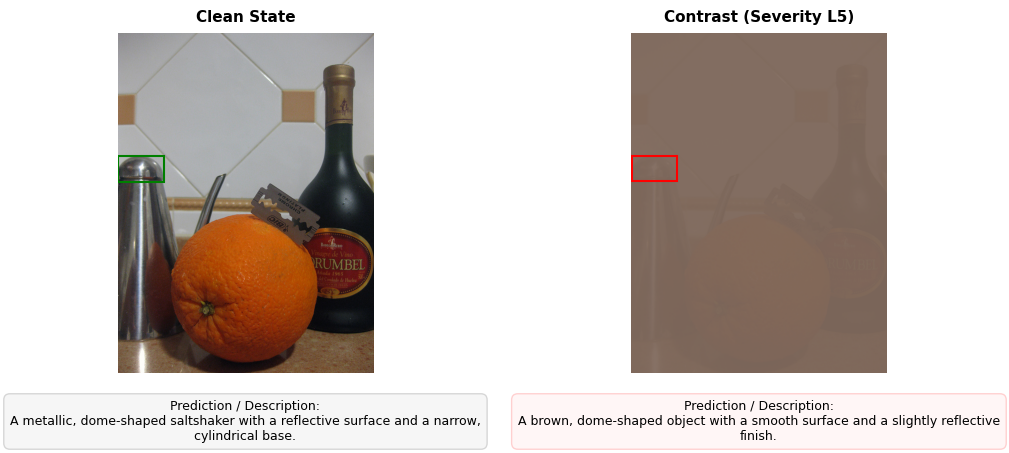

[Done] Exported publication-quality vector figure: qualitative_compare_idx_2_contrast.pdf



In [29]:
import os
import copy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_clean_vs_noise_sample(clean_dataset, sample_idx, noise_type="jpeg_compression", noise_severity=5, 
                                    clean_caption="Clean Caption", noise_caption="Noise Caption"):
    """
    Render side-by-side 1:1 comparison between Clean and Noisy (Level 5) images 
    for the same sample, along with dedicated caption boxes beneath each image.
    
    Parameters:
    -----------
    clean_dataset : Dataset object
        UniversalDataset initialized with perturber=None.
    sample_idx : int
        Data sample index to render.
    noise_type : str
        Corruption type name to apply (e.g. 'jpeg_compression', 'gaussian_noise', 'defocus_blur'...)
    noise_severity : int
        Corruption severity level (default: 5).
    clean_caption : str
        Text content / prediction displayed under the Clean image.
    noise_caption : str
        Text content / prediction displayed under the Noisy image.
    """
    print(f"-> Rendering qualitative comparison for Sample Index: {sample_idx} (Noise: {noise_type})...")

    # 1. Extract clean sample from dataset
    batch = clean_dataset[sample_idx]
    base_img = np.array(batch['image'])
    base_bboxes = batch['bboxes']
    base_masks = batch['masks']
    
    # Retrieve ann_id from metadata for descriptive export filename
    ann_id = batch.get('ann_id', batch.get('id', f"idx_{sample_idx}"))
    print(ann_id)

    # 2. Instantiate AddNoise perturbation module
    perturber = AddNoise(image_noise_type=noise_type, image_severity=noise_severity)

    # 3. Deepcopy data to isolate perturbation conditions
    img_c = base_img.copy()
    bboxes_c = copy.deepcopy(base_bboxes) if base_bboxes else None
    masks_c = [m.copy() if m is not None else None for m in base_masks] if base_masks else None

    # Apply perturbation via apply_to_data
    if bboxes_c:
        new_bboxes_c = [[bbox[0], bbox[1], bbox[2] - bbox[0], bbox[3] - bbox[1]] for bbox in bboxes_c]
        noisy_img, noisy_bboxes, noisy_masks = perturber.apply_to_data(
            image=img_c, bboxes=new_bboxes_c, masks=masks_c
        )
    else:
        noisy_img, noisy_bboxes, noisy_masks = perturber.apply_to_data(
            image=img_c, bboxes=None, masks=masks_c
        )

    if not isinstance(noisy_img, np.ndarray):
        noisy_img = np.array(noisy_img)

    # ==========================================================================
    # 4. Subplot setup: 1 row, 2 columns (report dimensions)
    # ==========================================================================
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    # --- LEFT: RENDER CLEAN IMAGE ---
    ax_clean = axes[0]
    ax_clean.imshow(base_img)
    ax_clean.set_title(f"Clean State", fontsize=11, fontweight='bold', pad=8)
    ax_clean.axis('off')
    
    # Render bounding box for clean image if present
    if base_bboxes:
        for bbox in base_bboxes:
            if bbox is None: continue
            x1, y1, x2, y2 = bbox
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='green', facecolor='none')
            ax_clean.add_patch(rect)
            
    # Format caption textbox below clean image
    ax_clean.text(0.5, -0.08, f"Prediction / Description:\n{clean_caption}", transform=ax_clean.transAxes,
                  ha='center', va='top', fontsize=9, wrap=True, 
                  bbox=dict(boxstyle='round,pad=0.5', facecolor='#f5f5f5', edgecolor='#d3d3d3', alpha=0.9))

    # --- RIGHT: RENDER NOISE LEVEL 5 IMAGE ---
    ax_noise = axes[1]
    ax_noise.imshow(noisy_img)
    ax_noise.set_title(f"{noise_type.replace('_', ' ').title()} (Severity L{noise_severity})", fontsize=11, fontweight='bold', pad=8)
    ax_noise.axis('off')
    
    # Render bounding box on corrupted image
    if noisy_bboxes:
        for bbox in noisy_bboxes:
            if bbox is None: continue
            x1, y1, x2, y2 = bbox
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none')
            ax_noise.add_patch(rect)

    # Format caption textbox below corrupted image
    ax_noise.text(0.5, -0.08, f"Prediction / Description:\n{noise_caption}", transform=ax_noise.transAxes,
                  ha='center', va='top', fontsize=9, wrap=True, 
                  bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff5f5', edgecolor='#ffcccc', alpha=0.9))

    # Adjust margins to prevent clipping
    plt.subplots_adjust(wspace=0.15, left=0.02, right=0.98, bottom=0.22, top=0.90)
    
    # Save high-resolution figure for publication appendix
    output_pdf_path = f"qualitative_compare_idx_{sample_idx}_{noise_type}.pdf"
    plt.savefig(output_pdf_path, format='pdf', bbox_inches='tight', pad_inches=0.02, dpi=300)
    plt.show()
    print(f"[Done] Exported publication-quality vector figure: {output_pdf_path}\n")

# ==========================================================================
# Example usage:
# ==========================================================================
my_dataset = UniversalDataset(hf_dataset=hf_dataset, dataset_name="cocostuff", perturber=None, local_path=None)
visualize_clean_vs_noise_sample(
    clean_dataset=my_dataset,
    sample_idx=2,
    noise_type="contrast",
    noise_severity=5,
    clean_caption="A metallic, dome-shaped saltshaker with a reflective surface and a narrow, cylindrical base.",
    noise_caption="A brown, dome-shaped object with a smooth surface and a slightly reflective finish."
)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import copy
import math

def visualize_benchmark_matrix(clean_dataset, index_list):
    """
    Render 110-test benchmark evaluation matrix for samples in range [start_index, end_index).
    Requirement: clean_dataset must be initialized with perturber=None.
    """
    # print(f"\n[VISUALIZATION] Rendering 110-test benchmark matrix from image {start_index} to {end_index-1}...")

    # ==========================================
    # 1. DEFINE 110 BENCHMARK MATRIX TEST SUITES
    # ==========================================
    configs = []

    # a. Clean Baselines (Mask & BBox)
    configs.append({"title": "Clean Base (Mask)", "params": {}, "mode": "mask"})
    # configs.append({"title": "Clean Base (BBox)", "params": {}, "mode": "bbox"})

    # b. Image Corruptions (15 types x 5 severities)
    img_noises = [
                  # 'gaussian_noise', 
                  # 'shot_noise', 
                  # 'impulse_noise',
                  # 'defocus_blur', 
                  # 'glass_blur', 
                  # 'motion_blur', 
                  # 'zoom_blur',
                  # 'snow', 
                  # 'frost', 
                  # 'fog', 
                  # 'brightness',
                  # 'contrast', 
                  # 'elastic_transform', 
                  # 'pixelate', 
                  'jpeg_compression'
                 ]
    for n_type in img_noises:
        for s in [5,]:
            configs.append({
                "title": f"{n_type} (Lv{s})",
                "params": {"image_noise_type": n_type, "image_severity": s},
                "mode": "mask"
            })

    # # c. Spatial BBox Noise (3 types x 5 severities)
    # bbox_noises = ["shift", "upscale", "downscale"]
    # for n_type in bbox_noises:
    #     for s in [1,3,5]:
    #         configs.append({
    #             "title": f"BBox: {n_type} (Lv{s})",
    #             "params": {"bbox_noise_type": n_type, "bbox_severity": s},
    #             "mode": "bbox"
    #         })
    #     if n_type != 'downscale':
    #         configs.append({"title": "Clean Base (BBox)", "params": {}, "mode": "bbox"})


    # # d. Mask Perturbations (4 types x 5 severities)
    # mask_noises = ["dilation", "erosion", "translation", "boundary_jitter"]
    # for n_type in mask_noises:
    #     for s in range(1, 6):
    #         configs.append({
    #             "title": f"Mask: {n_type} (Lv{s})",
    #             "params": {"mask_noise_type": n_type, "mask_severity": s},
    #             "mode": "mask"
    #         })

    # ==========================================
    # 2. RENDER MATRIX FOR EACH SAMPLE
    # ==========================================
    # actual_end = min(end_index, len(clean_dataset))
    for idx in index_list:
        print(f"-> Rendering sample index: {idx}...")

        # Extract clean sample from dataset
        batch = clean_dataset[idx]
        base_img = np.array(batch['image'])
        base_bboxes = batch['bboxes']
        base_masks = batch['masks']

        n_cols = 4  # Increased from 3 to 6 to make it much tighter vertically
        n_rows = math.ceil(len(configs) / n_cols)
        
        # Small figure footprint (e.g., width=7 inches fits nicely in a single column or full-width)
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4, 0.9 * n_rows))
        axes = axes.flatten()

        for i, cfg in enumerate(configs):
            ax = axes[i]
            params = cfg["params"]
            mode = cfg["mode"]

            # Instantiate AddNoise for current test
            perturber = AddNoise(**params) if params else None

            # Deepcopy sample data to isolate test conditions
            img_c = base_img.copy()
            bboxes_c = copy.deepcopy(base_bboxes) if base_bboxes else None
            masks_c = [m.copy() if m is not None else None for m in base_masks] if base_masks else None
            # print(bboxes_c)
            # Apply perturbation
            if perturber:
                new_bboxes_c = []
                for bbox in bboxes_c:
                    new_bboxes_c.append([bbox[0], bbox[1], bbox[2] - bbox[0], bbox[3] - bbox[1]])
                noisy_img, noisy_bboxes, noisy_masks = perturber.apply_to_data(
                    image=img_c, bboxes=new_bboxes_c, masks=masks_c
                )
            else:
                noisy_img, noisy_bboxes, noisy_masks = img_c, bboxes_c, masks_c

            # Render image
            if not isinstance(noisy_img, np.ndarray):
                noisy_img = np.array(noisy_img)
            ax.imshow(noisy_img)

            # Render region overlay (Mask or BBox)
            if mode == "mask" and noisy_masks:
                pass
                # for mask in noisy_masks:
                #     if mask is None:
                #         continue
                #     m_np = np.array(mask)
                #     # Green translucent mask overlay
                #     color_mask = np.zeros((*m_np.shape, 4))
                #     color_mask[m_np > 0] = [0, 1, 0, 0.45]
                #     ax.imshow(color_mask)

            elif mode == "bbox" and noisy_bboxes:
                for bbox in noisy_bboxes:
                    if bbox is None:
                        continue
                        
                    # 1. Input format: [xmin, ymin, xmax, ymax]
                    x1, y1, x2, y2 = bbox
                    
                    # 2. Compute width (w) and height (h) for matplotlib
                    w = x2 - x1
                    h = y2 - y1
                    
                    # 3. Draw bounding box rectangle
                    rect = patches.Rectangle((x1, y1), w, h, linewidth=1, edgecolor='red', facecolor='none')
                    ax.add_patch(rect)

            # High density styling
            ax.set_title(cfg["title"], fontsize=5, pad=3, fontweight='bold')
            ax.axis('off')

        # Hide completely empty axes
        for j in range(len(configs), len(axes)):
            axes[j].axis('off')

        # CRITICAL FOR PAPERS: Eliminate blank margins
        plt.subplots_adjust(wspace=0.04, hspace=0.25, left=0.01, right=0.99, bottom=0.01, top=0.95)
        
        # Save directly to high-quality vector PDF for LaTeX compilation
        if idx == 6:
            plt.savefig(f"benchmark_matrix_sample_{idx}.pdf", format='pdf', bbox_inches='tight', pad_inches=0.01, dpi=300)
        plt.show()



visualize_benchmark_matrix(UniversalDataset(hf_dataset=hf_dataset, dataset_name="cocostuff", perturber=None, local_path=None), [i for i in range(1,100)])

In [ ]:
import pandas as pd
from tqdm import tqdm
from torch.utils.data import DataLoader, Subset
from dam import DescribeAnythingModel
from transformers import SamModel, SamProcessor
import torch
import gc
import time
import numpy as np
from PIL import Image

def apply_sam(image, sam_model, sam_processor, input_points=None, input_boxes=None, input_labels=None):
    """
    Use Segment Anything Model (SAM) to extract pixel mask from Bounding Box prompt.
    Key interface bridging BBox (Noisy) -> SAM -> Mask -> DAM.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    inputs = sam_processor(image, input_points=input_points, input_boxes=input_boxes,
                           input_labels=input_labels, return_tensors="pt").to(device)
    
    # Cast inputs to float16 to conserve VRAM
    for k, v in inputs.items():
        if torch.is_floating_point(v):
            inputs[k] = v.to(torch.float16)
            
    with torch.no_grad():
        outputs = sam_model(**inputs)

    # Post-process masks to original image dimensions
    masks = sam_processor.image_processor.post_process_masks(
        outputs.pred_masks.cpu(),
        inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu()
    )[0][0]
    scores = outputs.iou_scores[0, 0]

    # Select mask candidate with highest predicted IoU
    mask_selection_index = scores.argmax()
    mask_np = masks[mask_selection_index].numpy()

    return mask_np

# =====================================================================
# --- 1. MODEL INFERENCE FUNCTIONS ---
# =====================================================================
def run_dam_inference(dam_model, image, regions, region_type="mask", img_id="Unknown"):
    """
    Execute inference with Describe Anything Model (DAM).
    Generates 3 detail granularities: Keyword (1 word), Phrase (short phrase), Detailed (comprehensive).
    """
    pred_keywords, pred_phrases, pred_detailed = [], [], []

    for i, region in enumerate(regions):
        # Skip items with region extraction failures to prevent batch crashes
        if region is None:
            print(f"\n[WARNING] Image '{img_id}' - Skipping region #{i+1} due to missing/corrupted {region_type.upper()}!")
            pred_keywords.append("")
            pred_phrases.append("")
            pred_detailed.append("")
            continue

        # 1. Keyword generation (Object identity recognition)
        keyword = dam_model.get_description(
            image, region,
            '<image>\nWhat is the object in the region? Answer with a single word or a short phrase.',
            streaming=False, temperature=0.0, top_p=0.5, num_beams=1, max_new_tokens=15
        )
        # pred_keywords.append(keyword)
        pred_keywords.append("")

        # # 2. Phrase generation (Short descriptive phrase)
        # phrase = dam_model.get_description(
        #     image, region,
        #     '<image>\nBriefly describe the region in a single short sentence.',
        #     streaming=False, temperature=0.2, top_p=0.5, num_beams=1, max_new_tokens=50
        # )
        # pred_phrases.append(phrase)
        pred_phrases.append("")

        # 3. Detailed caption generation (Comprehensive regional description)
        detailed = dam_model.get_description(
            image, region,
            '<image>\nDescribe the region in detail.',
            streaming=False, temperature=0.2, top_p=0.5, num_beams=1, max_new_tokens=512
        )
        pred_detailed.append(detailed)
        # pred_phrases.append("")

    return pred_keywords, pred_phrases, pred_detailed


# =====================================================================
# --- 2. MAIN EXECUTION PIPELINE ---
# =====================================================================
def main():
    img_noise_opts = ['gaussian_noise', 'defocus_blur', 'brightness', 'jpeg_compression']
    sev_opts = [1,3,5]
    for img_noise_opt in img_noise_opts:
        for sev_opt in sev_opts:
            if(img_noise_opt == 'gaussian_noise' and (sev_opt == 1)):
                continue
            # ---------------------------------------------------------
            # STEP 1: GPU MEMORY CLEANUP
            # ---------------------------------------------------------
            print("0. Cleaning up system memory...")
            if 'dam_model' in locals() or 'dam_model' in globals():
                del dam_model
            if 'sam_model' in locals() or 'sam_model' in globals():
                del sam_model
            if 'sam_processor' in locals() or 'sam_processor' in globals():
                del sam_processor
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            time.sleep(2)
        
            # ---------------------------------------------------------
            # STEP 2: LOAD MODELS (DAM & SAM) IN FP16
            # ---------------------------------------------------------
            print("-> Loading DAM model (3B)...")
            dam_model = DescribeAnythingModel(
                model_path="/kaggle/input/models/koahle/dam-3b/pytorch/default/1", # Update to your actual checkpoint path
                conv_mode="v1",
                prompt_mode="full+focal_crop",
                device_map="auto",
                torch_dtype=torch.float16  # Prevents CUDA OOM
            )
            dam_model.model.eval()
        
            print("-> Loading SAM model (facebook/sam-vit-huge)...")
            sam_processor = SamProcessor.from_pretrained("facebook/sam-vit-huge")
            sam_model = SamModel.from_pretrained(
                "facebook/sam-vit-huge",
                torch_dtype=torch.float16  # Keep SAM in FP16 for memory efficiency
            )
            sam_model.eval()
            device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
            sam_model.to(device)
            print("-> Successfully loaded both models in FP16 for VRAM safety!")
        
            # ---------------------------------------------------------
            # STEP 1: CONFIGURE BENCHMARK PERTURBATIONS
            # ---------------------------------------------------------
            print("1. Initializing perturbation engine...")
            # NOTE: To evaluate on CLEAN baseline data,
            # set all noise type parameters below to None.
        
            image_noise_type = img_noise_opt
            image_severity = sev_opt
            bbox_noise_type = None
            bbox_severity = 0
            mask_noise_type = None
            mask_severity = 0
            perturber = AddNoise(
                # ==========================================================
                # AXIS 1: FULL-IMAGE CORRUPTIONS (ImageNet-C)
                # ==========================================================
                # Supported: 'gaussian_noise', 'shot_noise', 'impulse_noise',
                #         'defocus_blur', 'glass_blur', 'motion_blur', 'zoom_blur',
                #         'snow', 'frost', 'fog', 'brightness',
                #         'contrast', 'elastic_transform', 'pixelate', 'jpeg_compression'
                image_noise_type=image_noise_type,
                # Severity level: from 1 (mild) to 5 (severe)
                image_severity=image_severity,
        
                # ==========================================================
                # AXIS 2: SPATIAL BBOX PERTURBATIONS (Shift, Upscale, Downscale)
                # ==========================================================
                # Supported:
                # 1. "upscale" (Context expansion)
                # 2. "downscale" (Object truncation)
                # 3. "shift" (Center translation / Misalignment)
        
                bbox_noise_type=bbox_noise_type,
                # Perturbation severity: from 1 to 5
                bbox_severity=bbox_severity,
        
                # ==========================================================
                # AXIS 3: MASK MORPHOLOGICAL PERTURBATIONS
                # ==========================================================
                # Supported:
                # 1. "dilation" (Boundary dilation)
                # 2. "erosion" (Boundary erosion)
                # 3. "translation" (Mask translation)
                # 4. "boundary_jitter" (Edge contour noise)
                mask_noise_type=mask_noise_type,
                # Mask destruction severity: from 1 to 5
                mask_severity=mask_severity
            )
        
            dataset_name = "cocostuff" # options: "lvis", "dlc_bench", "cocostuff"
            print("2. Initializing UniversalDataset...")
            # Initialize UniversalDataset with configured perturber
            if dataset_name == "dlc_bench":
                local_path = '/kaggle/input/datasets/ckhangnguyn/dlc-bench/DLC-Bench'
            else:
                local_path = None
            my_dataset = UniversalDataset(hf_dataset=hf_dataset, dataset_name=dataset_name, perturber=perturber, local_path = local_path)
        
            # ---------------------------------------------------------
            # STEP 2: DATASET CHUNKING (Prevents Kaggle runtime timeouts)
            # ---------------------------------------------------------
            start_index = 0     # Start sample index
            end_index = 2000     # End sample index
            actual_end_index = min(end_index, len(my_dataset)) 
        
            subset_indices = list(range(start_index, actual_end_index))
            my_subset = Subset(my_dataset, subset_indices)
            dataloader = DataLoader(my_subset, batch_size=1, shuffle=False, collate_fn=lambda x: x[0])
        
            # ---------------------------------------------------------
            # STEP 3: INPUT MODALITY SELECTION
            # ---------------------------------------------------------
            # 'mask': Ground-truth or perturbed mask -> DAM (Upper Bound)
            # 'bbox': Bounding box -> SAM -> Mask -> DAM
            inference_approach = "bbox" # or "mask"
        
            print(f"-> Selected extraction modality: {inference_approach.upper()}")
            print(f"-> Processing images {start_index} to {actual_end_index - 1}. Total: {len(my_subset)} images.")
        
            all_csv_rows = []
        
            # ---------------------------------------------------------
            # STEP 4: MAIN INFERENCE LOOP
            # ---------------------------------------------------------
            print("3. Starting model inference...")
            with torch.no_grad():
                for idx, batch in enumerate(tqdm(dataloader, desc="Processing images")):
                    image = batch['image']
                    csv_rows = batch['csv_rows']
                    current_img_id = csv_rows[0]['img_id'] if len(csv_rows) > 0 else f"Index_{idx}"
            
                    if inference_approach == "mask": 
                        regions_to_use = batch['masks']
        
                    elif inference_approach == "bbox":
                        regions_to_use = []
                        bboxes = batch['bboxes']
            
                        for bbox in bboxes:
                            if bbox is None:
                                regions_to_use.append(None)
                                continue
            
                            input_boxes = [[[bbox]]]
            
                            try:
                                mask_np = apply_sam(
                                    image=image,
                                    sam_model=sam_model,
                                    sam_processor=sam_processor,
                                    input_boxes=input_boxes
                                )
        
                                # ==========================================
                                # SAFETY GUARD: Check for empty / all-zero SAM masks
                                # ==========================================
                                if not np.any(mask_np):
                                    print(f"\n[WARNING] BBox severely degraded; SAM failed to segment target. Skipping.")
                                    regions_to_use.append(None)
                                    continue
            
                                mask_pil = Image.fromarray((mask_np * 255).astype(np.uint8))
                                regions_to_use.append(mask_pil)
            
                                # 🔥 FREE SAM MEMORY
                                del mask_np
            
                            except Exception as e:
                                print(f"[ERROR] SAM failure on BBox {bbox}: {e}")
                                regions_to_use.append(None)
            
                        torch.cuda.empty_cache()  # 🔥 after SAM batch
            
                    # DAM inference
                    pred_keywords, pred_phrases, pred_detailed = run_dam_inference(
                        dam_model=dam_model,
                        image=image,
                        regions=regions_to_use,
                        region_type=inference_approach,
                        img_id=current_img_id
                    )
            
                    torch.cuda.empty_cache()  # 🔥 after DAM
            
                    for i, row in enumerate(csv_rows):
                        row["pred_keyword"] = pred_keywords[i]
                        row["pred_phrase"] = pred_phrases[i]
                        row["pred_detailed"] = pred_detailed[i]
                        all_csv_rows.append(row)
            
                    # 🔥 FINAL CLEANUP PER IMAGE
                    del regions_to_use
                    del pred_keywords, pred_phrases, pred_detailed
                    del image
            
                    gc.collect()
                    torch.cuda.empty_cache()
        
            # ---------------------------------------------------------
            # STEP 5: EXPORT PREDICTIONS TO CSV FOR BENCHMARK EVALUATORS
            # ---------------------------------------------------------
            print("4. Exporting results to CSV...")
            df = pd.DataFrame(all_csv_rows)
            
            # Automated filename reflecting experiment parameters
            # Example: dam_cocostuff_bbox_expansion_sev2_0_to_3000.csv
            noise_label = perturber.bbox_noise_type if inference_approach == "bbox" else perturber.mask_noise_type
            severity_label = perturber.bbox_severity if inference_approach == "bbox" else perturber.mask_severity
            noise_str = f"{noise_label}_sev{severity_label}" if noise_label else "clean"
            
            csv_filename = f"dam_{dataset_name}_{inference_approach}_{image_noise_type}_level_{image_severity}_{start_index}_to_{actual_end_index}.csv"
        
            # Save with UTF-8-SIG encoding for universal compatibility
            df.to_csv(csv_filename, index=False, encoding='utf-8-sig')
        
            print(f"-> Done! Saved {len(df)} region annotations to {csv_filename}")

if __name__ == "__main__":
    main()

## End of Inference Pipeline
